# Project 1 · Step 5 — DCF and bid calibration (Nordsøen Midt, Hesselø)

**Question.** Which combinations of capex, WACC and yield give NPV = 0 at Vattenfall's awarded strikes
(NSM DKK 504/MWh, DK1, 1,005 MW; Hesselø DKK 542/MWh, DK2, 795 MW), and what strike does my base case imply?

**Model** (`dcf_model.py`, tested in `tests/`): real 2026 DKK (NPI May 2026 = strike base), annual cash flows
2026–2063, CfD settled monthly with the running net cap (B9) and one-month payment lag (B7), taxes on nominal
depreciation deflated to real, two-rate discounting (CfD period / merchant tail).

Status tags as in `contract_assumptions.md`: **Doc** tender documents · **Ext** named outside source ·
**Asm** my assumption.

### Step-5 assumptions register (new in this step)
| # | Assumption | Value | Status |
|---|---|---|---|
| S5-1 | NPV date | bid deadline 20 May 2026; annual flows mid-year | Asm |
| S5-2 | Real ↔ nominal | NPI path 2 %/yr from May 2026 (contract A5) — used only for tax depreciation, guarantee fees | Asm |
| S5-3 | Strike | constant real (A4 NPI indexation); the Sep(y−1) reset lag is shown as a sensitivity | Doc / Asm |
| S5-4 | Net cap in 2026 DKK | cap × NPI May 2026 / NPI May 2025 (=1.027); May 2025 used as the "1 Jun 2025" base | Doc / Asm |
| S5-5 | IDC | not added as a cash flow: unlevered real WACC applied from the spend date already charges the cost of capital during construction. Reported as "implicit IDC" (capex compounded to COD at the CfD WACC) | Asm |
| S5-6 | Discount rate before COD | CfD-period WACC (development and construction) | Asm |
| S5-7 | Tail discounting | "chained": tail flows discounted at the CfD WACC to 1 Jan 2053, then at the tail WACC; "full" (tail WACC from today) as a sensitivity | Asm |
| S5-8 | Merchant sales | metered × RP: output is zero in negative-price hours (C1), so revenue per metered MWh = AAP-weighted floored price; variable costs on MWh actually sold | Doc / Asm |
| S5-9 | Tax timing | paid in the income year (aconto); CfD taxed on accrual; remaining tax balances written off in the last operating year; decommissioning deductible | Asm |
| S5-10 | Owner's devex | in the 15 % plant pool with DEA development | Asm |
| S5-11 | Yield P90 (20-yr mean) | 1 − 1.2816·√(σ²_IAV/20 + 6 %²); σ_IAV from step 2 | Asm |
| S5-12 | Availability 93.5 % | the extra 2.5 points are unscheduled → reduce AAP and metered output | Ext (Vattenfall 2025) / Asm |
| S5-13 | 20 MW yield uplift | DEA full-load hours 4,550 (20 MW) ÷ 4,400 (15 MW) = +3.4 % | Ext / Asm |
| S5-14 | AF25 leap-day handling | DEA dropped 31 Dec in 2008 (inferred, §2) | Asm (evidence-based) |
| S5-15 | Missing ERA5 1995 | capture factors from 2008/2009 only, weights renormalised 0.467/0.533; price levels still use all three climate years | Asm |
| S5-16 | WACC solver | tail WACC = CfD WACC + 2.0 pp (the base spread) | Asm |

In [1]:
import warnings; warnings.filterwarnings("ignore")
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import dcf_model as d

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

# chart style (reference palette, recessive grid, one axis per chart)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "lines.linewidth": 2, "legend.frameon": False})

inp = d.load_inputs()
SC, MB = {}, {}
for s in d.SITES:
    SC[s], MB[s] = d.build_price_scenarios(inp, s)
BASE = {s: d.make_params(inp, s) for s in d.SITES}
print("Climate years with ERA5 AAP:", {s: MB[s].climate_years_used for s in d.SITES})

Climate years with ERA5 AAP: {'NSM': (2008, 2009), 'HES': (2008, 2009)}


## 1. Inputs as used
Capex from `step4/cost_inputs.yaml` (DEA 2030 column, site-adjusted; Ext + Asm), yield = step-2 ERA5 2006–2025 P50
with base losses (Asm), net cap B9 (Doc/Ext ⚠ site).

In [2]:
ys = inp.yield_summary
rows = []
for s, p in BASE.items():
    sub = ys[ys.site == s]
    iav = sub.aap_proxy_GWh.std() / sub.aap_proxy_GWh.mean()
    rows.append({"site": s, "MW": p.mw, "strike": p.strike, "capex all-in DKK m": p.capex_total,
                 "DKK m/MW": p.capex_per_mw, "AAP P50 GWh": p.aap_monthly.sum() / 1e3,
                 "metered P50 GWh": p.metered_monthly.sum() / 1e3, "IAV σ": iav,
                 "P90 factor": d.p90_factor(iav), "net cap DKK m (2026)": p.net_cap})
inputs_tbl = pd.DataFrame(rows).set_index("site")
P90 = inputs_tbl["P90 factor"].to_dict()
inputs_tbl.style.format("{:,.3f}", subset=["IAV σ", "P90 factor"]).format("{:,.1f}", subset=inputs_tbl.columns.drop(["IAV σ", "P90 factor"]))

,MW,strike,capex all-in DKK m,DKK m/MW,AAP P50 GWh,metered P50 GWh,IAV σ,P90 factor,net cap DKK m (2026)
site,,,,,,,,,
NSM,"1,005.0",504.0,"22,438.0",22.3,"4,820.2","4,651.2",0.035,0.922,"16,126.3"
HES,795.0,542.0,"17,665.7",22.2,"3,589.3","3,463.5",0.053,0.922,"22,494.7"


## 2. Price scenarios (method B) and checks

**Timing check.** The AF25 hourly prices should correlate (negatively) with site AAP for the *same* weather year
and not for others. They do: the matching ERA5 year is the only one with a negative correlation. For 2008 (a leap
year) the correlation from March onwards peaks at lag 0 only if 31 Dec is dropped, so the DEA kept 29 Feb (S5-14).

In [3]:
af = inp.af25_hourly
chk = []
for s, z in [("NSM", "DK1"), ("HES", "DK2")]:
    for c in (2008, 2009):
        p = af[af.sim == 2040][f"{z}_{c}"].to_numpy(float)
        corr = {y: np.corrcoef(d.align_era5_to_af25(inp.aap[s], y), p)[0, 1] for y in range(2006, 2026)}
        other = [v for y, v in corr.items() if y != c]
        a29 = d.align_era5_to_af25(inp.aap[s], c, leap_drop="feb29"); a31 = d.align_era5_to_af25(inp.aap[s], c)
        mar = slice(60 * 24, None)
        chk.append({"site": s, "climate yr": c, "corr same yr": corr[c], "corr other yrs (max)": max(other),
                    "Mar–Dec corr, drop 29 Feb": np.corrcoef(a29[mar], p[mar])[0, 1],
                    "Mar–Dec corr, drop 31 Dec": np.corrcoef(a31[mar], p[mar])[0, 1]})
pd.DataFrame(chk).style.format("{:.3f}", subset=pd.IndexSlice[:, ["corr same yr", "corr other yrs (max)", "Mar–Dec corr, drop 29 Feb", "Mar–Dec corr, drop 31 Dec"]])

,site,climate yr,corr same yr,corr other yrs (max),"Mar–Dec corr, drop 29 Feb","Mar–Dec corr, drop 31 Dec"
0,NSM,2008,-0.228,0.236,-0.093,-0.252
1,NSM,2009,-0.182,0.339,-0.095,-0.095
2,HES,2008,-0.106,0.245,-0.071,-0.169
3,HES,2009,-0.172,0.397,-0.074,-0.074


**Capture factor vs the DEA's published ratio (method §3 B5).** Annual AAP-weighted RP ÷ annual spot from the
pairing, against the DEA's own offshore-wind-weighted ÷ spot (sheet *Elpriser*, Ext). The gap is large and is not a
timing error (above): the hourly AF25 prices simply do not concentrate low prices in windy hours to the degree the
published fleet ratio implies, and AF25's strong seasonal shape (winter prices ~2–3× summer by 2050) favours a
winter-peaking wind profile. I keep method B as S1 and run the DEA's published ratio as an extra sensitivity
**S1-B′** (method §3 B′; Ext ratio, Asm monthly shape).

In [4]:
rows = []
for s in d.SITES:
    z = d.SITES[s]["zone"]; w = BASE[s].aap_monthly
    for i, y in enumerate(d.AF25_SIM_YEARS):
        cf_within = (MB[s].cf[i] * w).sum() / w.sum()
        cf_annual = (MB[s].cf[i] * MB[s].seasonal[i] * w).sum() / w.sum()
        dea = inp.af25_annual["Havvind"][z][i] / inp.af25_annual["Spot"][z][i]
        rows.append({"site": s, "year": y, "CF within month (method B)": cf_within,
                     "CF annual incl. seasonal (method B)": cf_annual, "DEA fleet offshore ÷ spot": dea})
cf_tbl = pd.DataFrame(rows).set_index(["site", "year"])
hist = inp.hist_monthly.assign(yr=lambda x: x.month.str[:4].astype(int))
cf_tbl.style.format("{:.3f}")

,HES,NSM
20-yr avg RP 2033–52,,
S1 AF25 central,434.9,403.8
S2 weather low,383.6,355.4
S2 weather high,480.9,443.2
S3 low gas (−15 %),369.6,343.2
"S4 low PtX (−20 %, CF −0.10)",308.0,285.1
S5 historical CF,438.9,422.5
S1-B′ DEA fleet ratio,326.0,358.1


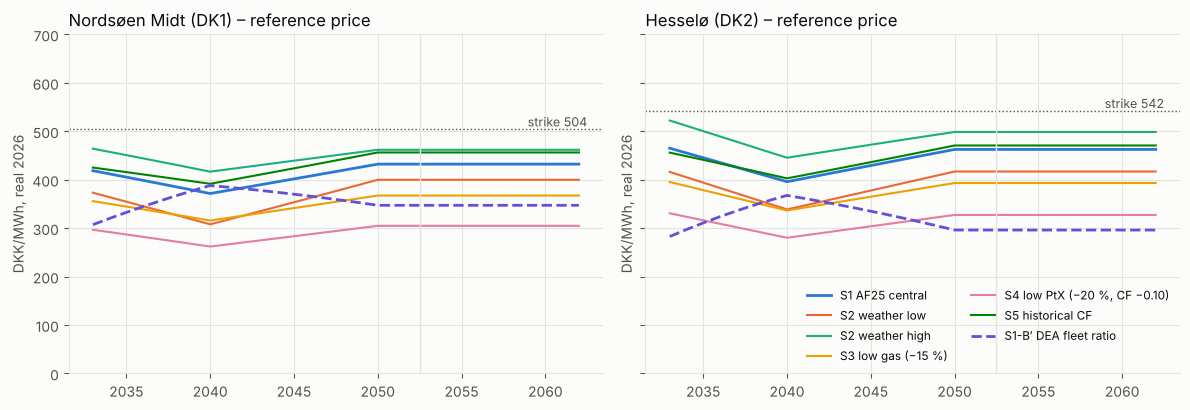

In [5]:
ORDER = ["S1", "S2_low", "S2_high", "S3", "S4", "S5", "S1_Bprime"]
LABEL = {"S1": "S1 AF25 central", "S2_low": "S2 weather low", "S2_high": "S2 weather high",
         "S3": "S3 low gas (−15 %)", "S4": "S4 low PtX (−20 %, CF −0.10)", "S5": "S5 historical CF",
         "S1_Bprime": "S1-B′ DEA fleet ratio"}
yrs = np.arange(2033, 2063)
rp_tbl = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, s in zip(axes, d.SITES):
    w = BASE[s].aap_monthly
    for i, k in enumerate(ORDER):
        sc = SC[s][k]; r = sc.annual_rp(w); m = np.isin(sc.years, yrs)
        rp_tbl[(s, k)] = r[m]
        ax.plot(yrs, r[m], color=PAL[i], lw=2 if k in ("S1", "S1_Bprime") else 1.5,
                ls="--" if k == "S1_Bprime" else "-", label=LABEL[k])
    ax.axhline(BASE[s].strike, color=INK2, lw=1, ls=":")
    ax.text(2062.5, BASE[s].strike, f"strike {BASE[s].strike:.0f}", color=INK2, va="bottom", ha="right", fontsize=9)
    ax.axvline(2052.5, color=GRID, lw=1); ax.set_title(f"{d.SITES[s]['name']} ({d.SITES[s]['zone']}) – reference price", loc="left")
    ax.set_ylabel("DKK/MWh, real 2026"); ax.set_ylim(0, 700)
axes[1].legend(loc="lower right", fontsize=8.5, ncol=2)
fig.tight_layout(); fig.savefig(OUT / "fig_price_scenarios.png", dpi=150)
rp_df = pd.DataFrame(rp_tbl, index=yrs)
rp_df.loc[2033:2052].mean().unstack(0).loc[ORDER].rename(index=LABEL).rename_axis("20-yr avg RP 2033–52")

## 3. Base case (S1, base costs, P50, WACC 5.0 % / 7.0 %)

In [6]:
RES = {s: d.run_model(BASE[s], SC[s]["S1"]) for s in d.SITES}
BE = {s: d.breakeven_strike(BASE[s], SC[s]["S1"]) for s in d.SITES}
summary = pd.DataFrame({s: {
    "NPV at awarded strike (DKK m)": RES[s].npv,
    "NPV per MW (DKK m/MW)": RES[s].npv / BASE[s].mw,
    "Break-even strike (DKK/MWh)": BE[s],
    "Gap vs awarded (DKK/MWh)": BE[s] - BASE[s].strike,
    "Gap vs awarded (%)": 100 * (BE[s] / BASE[s].strike - 1),
    "Implied CfD WACC at awarded strike (%)": 100 * d.solve_wacc(BASE[s], SC[s]["S1"]),
    "Implicit IDC to COD (DKK m)": RES[s].idc_implicit,
    "Net cap used (max share)": RES[s].cap_used_share,
    "Cap headroom: max avg subsidy (DKK/MWh of AAP)": BASE[s].net_cap * 1e6 / (20 * BASE[s].aap_monthly.sum()),
    "Net cap exhausted": RES[s].cap_exhausted or "no",
} for s in d.SITES})
summary

,NSM,HES
NPV at awarded strike (DKK m),"-1,471.8",-844.9
NPV per MW (DKK m/MW),-1.5,-1.1
Break-even strike (DKK/MWh),546.6,574.9
Gap vs awarded (DKK/MWh),42.6,32.9
Gap vs awarded (%),8.5,6.1
Implied CfD WACC at awarded strike (%),4.3,4.5
Implicit IDC to COD (DKK m),"2,612.7","2,032.7"
Net cap used (max share),0.6,0.4
Cap headroom: max avg subsidy (DKK/MWh of AAP),167.3,313.4
Net cap exhausted,no,no


In [7]:
pd.concat({s: d.pv_breakdown(RES[s]) for s in d.SITES}, axis=1).rename_axis("PV at bid date, DKK m")

,NSM,HES
"PV at bid date, DKK m",,
CfD payments (net),"4,570.8","3,592.1"
Market sales,"21,252.1","17,065.6"
Opex,"-7,221.2","-5,589.3"
Decommissioning,-324.8,-260.2
Capex,"-18,139.3","-14,263.7"
Tax,"-1,609.3","-1,389.5"
NPV,"-1,471.8",-844.9


In [8]:
cols = ["aap_gwh", "metered_gwh", "rp", "cfd_accrued", "cfd_cash", "merchant", "opex", "capex", "ebitda",
        "tax_depr_nominal", "tax", "fcf", "df", "pv"]
for s in d.SITES:
    RES[s].annual[cols].to_csv(OUT / f"cashflows_base_{s}.csv", float_format="%.3f")
RES["NSM"].annual[cols].loc[[2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2040, 2045, 2052, 2053, 2062, 2063]]

,aap_gwh,metered_gwh,rp,cfd_accrued,cfd_cash,merchant,opex,capex,ebitda,tax_depr_nominal,tax,fcf,df,pv
2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.1,0.0,0.0,0.0,-20.1,1.0,-20.0
2027,0.0,0.0,0.0,0.0,0.0,0.0,3.0,532.8,-3.0,0.0,-0.7,-535.2,0.9,-506.8
2028,0.0,0.0,0.0,0.0,0.0,0.0,3.0,532.8,-3.0,0.0,-0.7,-535.1,0.9,-482.6
2029,0.0,0.0,0.0,0.0,0.0,0.0,2.9,"4,210.5",-2.9,141.0,-29.8,"-4,183.6",0.9,"-3,593.5"
2030,0.0,0.0,0.0,0.0,0.0,0.0,2.8,"7,058.3",-2.8,141.0,-29.2,"-7,032.0",0.8,"-5,752.5"
2031,0.0,0.0,0.0,0.0,0.0,0.0,2.8,"7,058.3",-2.8,141.0,-28.6,"-7,032.5",0.8,"-5,478.9"
2032,0.0,0.0,0.0,0.0,0.0,0.0,2.7,"3,025.0",-2.7,141.0,-28.1,"-2,999.7",0.7,"-2,225.7"
2033,"4,820.2","4,651.2",418.7,411.3,569.9,"1,947.3",642.8,0.0,"1,715.8","3,611.2",-312.4,"2,186.8",0.7,"1,542.8"
2034,"4,820.2","4,651.2",412.1,443.1,443.9,"1,916.6",637.8,0.0,"1,722.0","2,956.4",-174.9,"1,897.6",0.7,"1,272.2"
2035,"4,820.2","4,651.2",405.4,475.1,475.5,"1,885.7",637.8,0.0,"1,723.1","2,519.3",-83.5,"1,807.0",0.6,"1,153.3"


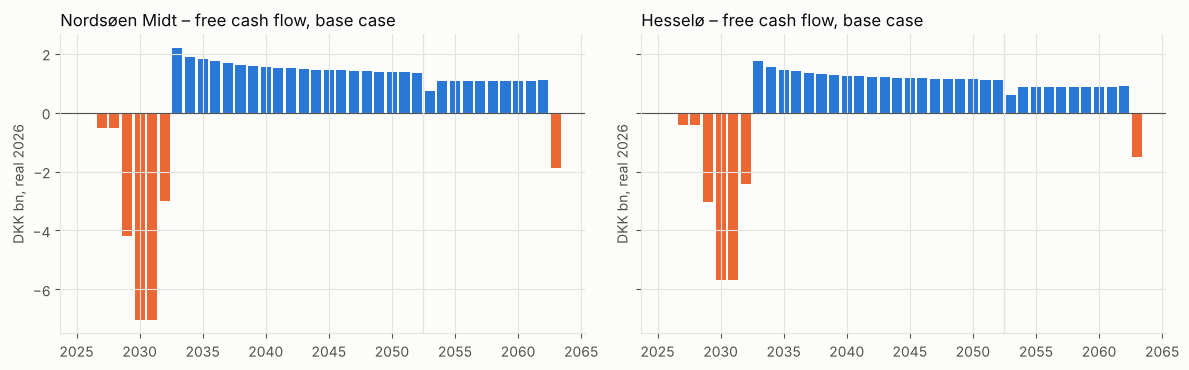

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, s in zip(axes, d.SITES):
    a = RES[s].annual
    ax.bar(a.index, a["fcf"] / 1e3, width=0.8, color=[PAL[0] if v >= 0 else PAL[1] for v in a["fcf"]])
    ax.axhline(0, color=INK2, lw=0.8); ax.axvline(2052.5, color=GRID, lw=1)
    ax.set_title(f"{d.SITES[s]['name']} – free cash flow, base case", loc="left"); ax.set_ylabel("DKK bn, real 2026")
fig.tight_layout(); fig.savefig(OUT / "fig_cashflow_base.png", dpi=150)

## 4. Price scenarios S1–S5 (+ S1-B′): NPV, break-even strike and the net cap
Break-even "none" means no strike gives NPV = 0 because the net cap caps the subsidy whatever the strike.

In [10]:
def be_or_none(p, sc):
    k = d.breakeven_strike(p, sc)
    return k

scen_rows = []
for s in d.SITES:
    for k in ORDER:
        r = d.run_model(BASE[s], SC[s][k])
        be = be_or_none(BASE[s], SC[s][k])
        rbe = d.run_model(replace(BASE[s], strike=be), SC[s][k]) if np.isfinite(be) else None
        scen_rows.append({"site": s, "scenario": LABEL[k],
            "avg RP 2033–52": rp_df.loc[2033:2052, (s, k)].mean(),
            "NPV @ awarded (DKK m)": r.npv, "ΔNPV vs S1": r.npv - RES[s].npv,
            "break-even strike": be,
            "cap exhausted @ awarded": r.cap_exhausted or "no", "cap used @ awarded": r.cap_used_share,
            "cap exhausted @ break-even": (rbe.cap_exhausted or "no") if rbe else "–",
            "subsidy lost to cap (DKK m)": r.subsidy_lost})
scen_tbl = pd.DataFrame(scen_rows).set_index(["site", "scenario"])
scen_tbl.to_csv(OUT / "scenarios.csv", float_format="%.2f")
CAPLIM = "cap-limited: no NPV=0 strike"
scen_tbl.assign(**{"break-even strike": scen_tbl["break-even strike"].map(lambda v: f"{v:,.1f}" if np.isfinite(v) else CAPLIM)})

avg RP 2033–52  NPV @ awarded (DKK m)  ΔNPV vs S1             break-even strike cap exhausted @ awarded  cap used @ awarded cap exhausted @ break-even  \
site scenario                                                                                                                                                                               
NSM  S1 AF25 central                        403.8               -1,471.8         0.0                         546.6                      no                 0.6                         no   
     S2 weather low                         355.4               -1,657.9      -186.1                         649.3                      no                 0.9                    2043-08   
     S2 weather high                        443.2               -1,296.5       175.3                         541.5                      no                 0.4                         no   
     S3 low gas (−15 %)                     343.2               -1,882.6      -410.8                         779.2                      no                 1.0                    2040-07   
     S4 low PtX (−20 %, CF −0.10)           285.1               -3,519.1    -2,047.3  cap-limited: no NPV=0 strike                 2047-09                 1.0                          –   
     S5 historical CF                       422.5               -1,264.0       207.8                         540.6                      no                 0.5                         no   
     S1-B′ DEA fleet ratio                  358.1               -2,047.7      -575.8                         683.4                      no                 0.9                    2043-04   
HES  S1 AF25 central                        434.9                 -844.9         0.0                         574.9                      no                 0.4                         no   
     S2 weather low                         383.6               -1,053.6      -208.6                         583.0                      no                 0.5                         no   
     S2 weather high                        480.9                 -685.0       159.9                         568.6                      no                 0.2                         no   
     S3 low gas (−15 %)                     369.6               -1,171.7      -326.7                         587.6                      no                 0.6                         no   
     S4 low PtX (−20 %, CF −0.10)           308.0               -1,482.3      -637.4                         599.7                      no                 0.8                         no   
     S5 historical CF                       438.9                 -777.7        67.3                         572.2                      no                 0.3                         no   
     S1-B′ DEA fleet ratio                  326.0               -1,665.3      -820.4                         606.8                      no                 0.7                         no   

                                   subsidy lost to cap (DKK m)  
site scenario                                                   
NSM  S1 AF25 central                                       0.0  
     S2 weather low                                        0.0  
     S2 weather high                                       0.0  
     S3 low gas (−15 %)                                    0.0  
     S4 low PtX (−20 %, CF −0.10)                      5,156.7  
     S5 historical CF                                      0.0  
     S1-B′ DEA fleet ratio                                 0.0  
HES  S1 AF25 central                                       0.0  
     S2 weather low                                        0.0  
     S2 weather high                                       0.0  
     S3 low gas (−15 %)                                    0.0  
     S4 low PtX (−20 %, CF −0.10)                          0.0  
     S5 historical CF                                      0.0  
     S1-B′ DEA fleet ratio         

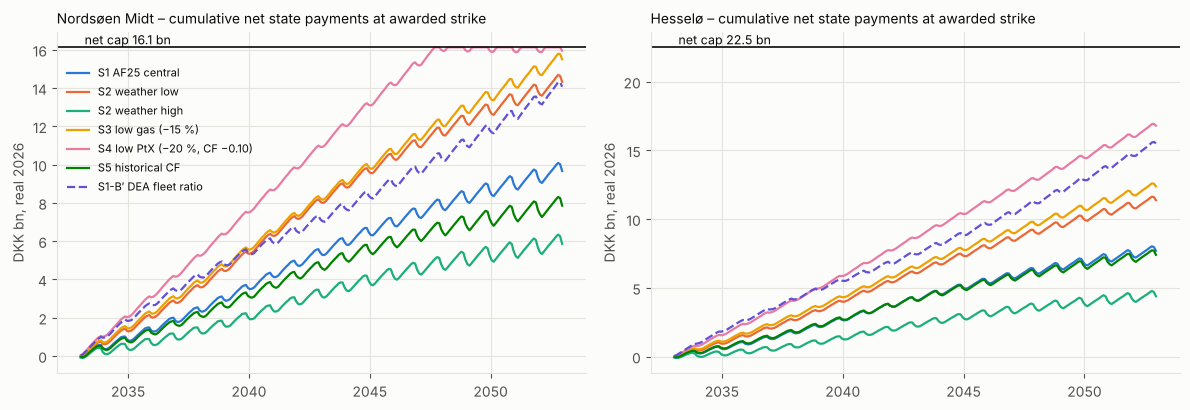

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, s in zip(axes, d.SITES):
    for i, k in enumerate(ORDER):
        m = d.run_model(BASE[s], SC[s][k]).monthly
        m = m[m.year < BASE[s].cfd_end]
        t = m.year + (m.month - 0.5) / 12
        ax.plot(t, m.cfd_paid.cumsum() / 1e3, color=PAL[i], lw=1.6, ls="--" if k == "S1_Bprime" else "-", label=LABEL[k])
    ax.axhline(BASE[s].net_cap / 1e3, color=INK, lw=1.2)
    ax.text(2033.2, BASE[s].net_cap / 1e3, f"net cap {BASE[s].net_cap/1e3:.1f} bn", va="bottom", fontsize=9)
    ax.set_title(f"{d.SITES[s]['name']} – cumulative net state payments at awarded strike", loc="left", fontsize=10)
    ax.set_ylabel("DKK bn, real 2026"); ax.set_xticks(range(2035, 2055, 5))
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, 0.93))
fig.tight_layout(); fig.savefig(OUT / "fig_net_cap.png", dpi=150)

**Why NSM is fragile and Hesselø is not.** The net cap divided by 20 years of P50 AAP is the average subsidy the cap can
pay: ≈ DKK 167/MWh for NSM and ≈ 313/MWh for Hesselø (table in §3). So NSM's strike can only exceed the average
reference price by ~167 before the cap starts to bind; below that, a higher strike just uses the cap up sooner.
That is why break-even strikes for NSM jump (or disappear) once a case pushes them above ~570–600.

## 5. Which capex / WACC / yield combinations give NPV = 0 at the awarded strike?
Solver: CfD-period WACC that sets NPV = 0 at 504 / 542 (tail WACC = CfD + 2 pp, S5-16), over a grid of all-in capex
(DKK m/MW, excl. IDC; scaling DEA base + contingency + owner devex, Energinet fixed) and four yield cases.

In [12]:
CAPEX_GRID = np.arange(16.0, 27.01, 1.0)
YIELD_CASES = {"P90": dict(yield_factor=None), "P50": dict(), "P10": dict(yield_factor=None),
               "P50, wake 13 %": dict(internal_wake=0.13)}
def yield_params(s, case):
    kw = dict(YIELD_CASES[case])
    if case == "P90": kw["yield_factor"] = P90[s]
    if case == "P10": kw["yield_factor"] = 2 - P90[s]
    return d.make_params(inp, s, **kw)

wacc_rows = []
for s in d.SITES:
    for case in YIELD_CASES:
        p0 = yield_params(s, case)
        for x in CAPEX_GRID:
            r = d.solve_wacc(d.set_capex_per_mw(p0, x), SC[s]["S1"])
            wacc_rows.append({"site": s, "yield": case, "capex DKK m/MW": x, "CfD WACC for NPV=0 (%)": 100 * r})
wacc_grid = pd.DataFrame(wacc_rows)
wacc_grid.to_csv(OUT / "wacc_solver_grid.csv", index=False, float_format="%.3f")
wacc_grid.pivot_table(index="capex DKK m/MW", columns=["site", "yield"], values="CfD WACC for NPV=0 (%)")

site           HES                        NSM                       
yield          P10 P50 P50, wake 13 % P90 P10 P50 P50, wake 13 % P90
capex DKK m/MW                                                      
16.0           7.9 7.1            6.7 6.2 7.7 6.9            6.5 6.1
17.0           7.4 6.6            6.2 5.7 7.2 6.4            6.0 5.6
18.0           6.9 6.1            5.8 5.3 6.7 5.9            5.6 5.1
19.0           6.4 5.7            5.3 4.9 6.2 5.5            5.2 4.7
20.0           6.0 5.3            4.9 4.5 5.8 5.1            4.8 4.3
21.0           5.6 4.9            4.6 4.1 5.4 4.7            4.4 4.0
22.0           5.3 4.5            4.2 3.8 5.1 4.4            4.1 3.6
23.0           4.9 4.2            3.9 3.5 4.7 4.0            3.7 3.3
24.0           4.6 3.9            3.6 3.2 4.4 3.7            3.4 3.0
25.0           4.3 3.6            3.3 2.9 4.1 3.4            3.1 2.7
26.0           4.0 3.3            3.0 2.6 3.8 3.2            2.9 2.5
27.0           3.7 3.1            2.8 2.4 3.6 2.9            2.6 2.2

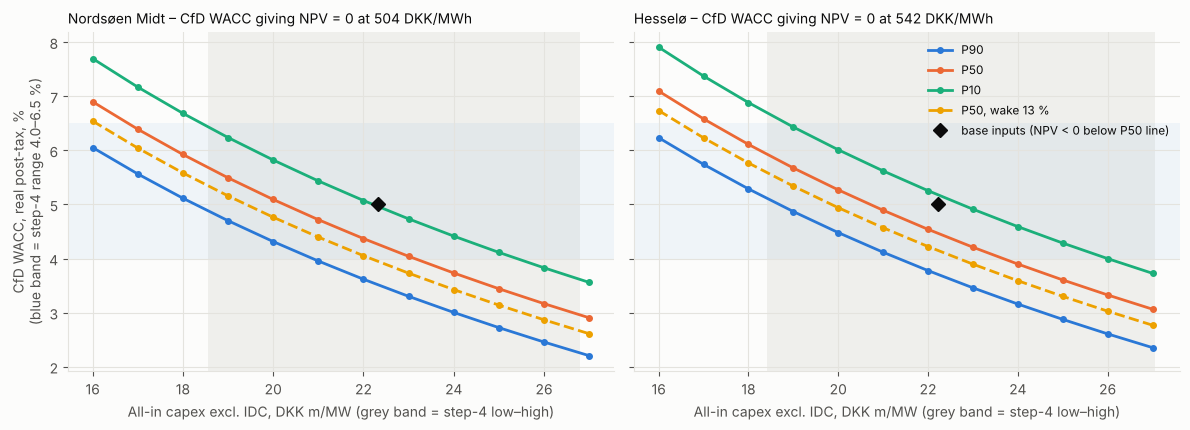

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, s in zip(axes, d.SITES):
    for i, case in enumerate(YIELD_CASES):
        g = wacc_grid[(wacc_grid.site == s) & (wacc_grid["yield"] == case)]
        ax.plot(g["capex DKK m/MW"], g["CfD WACC for NPV=0 (%)"], color=PAL[i], marker="o", ms=4,
                ls="--" if "wake" in case else "-", label=case)
    lo, hi = inp.cost["capex"][s]["capex_all_in_mdkk_per_mw"]["low"], inp.cost["capex"][s]["capex_all_in_mdkk_per_mw"]["high"]
    ax.axvspan(lo, hi, color=GRID, alpha=0.5, lw=0)
    ax.axhspan(4.0, 6.5, color=PAL[0], alpha=0.06, lw=0)
    ax.plot([BASE[s].capex_per_mw], [5.0], marker="D", color=INK, ms=7, ls="none", label="base inputs (NPV < 0 below P50 line)")
    ax.set_title(f"{d.SITES[s]['name']} – CfD WACC giving NPV = 0 at {BASE[s].strike:.0f} DKK/MWh", loc="left", fontsize=10)
    ax.set_xlabel("All-in capex excl. IDC, DKK m/MW (grey band = step-4 low–high)")
axes[0].set_ylabel("CfD WACC, real post-tax, %\n(blue band = step-4 range 4.0–6.5 %)")
axes[1].legend(fontsize=8.5, loc="upper right")
fig.tight_layout(); fig.savefig(OUT / "fig_wacc_vs_capex.png", dpi=150)

In [14]:
# Break-even capex at base WACC, and break-even strike over capex × WACC (P50, S1)
be_capex = pd.DataFrame({s: {case: d.solve_capex(yield_params(s, case), SC[s]["S1"]) for case in YIELD_CASES}
                         for s in d.SITES})
be_capex.index.name = "capex DKK m/MW for NPV=0 @ awarded, WACC 5/7 %"
display(be_capex)
grid = []
for s in d.SITES:
    for x in [18, 20, 22, 24, 26]:
        for r in [0.04, 0.045, 0.05, 0.055, 0.06, 0.065]:
            p = replace(d.set_capex_per_mw(BASE[s], x), wacc_cfd=r, wacc_tail=r + 0.02)
            grid.append({"site": s, "capex": x, "CfD WACC %": 100 * r, "BE strike": d.breakeven_strike(p, SC[s]["S1"])})
be_grid = pd.DataFrame(grid).pivot_table(index=["site", "capex"], columns="CfD WACC %", values="BE strike")
be_grid.to_csv(OUT / "breakeven_strike_grid.csv", float_format="%.1f")
print("NaN = cap-limited (no strike gives NPV = 0). Very high values = the cap binds early at that strike.")
be_grid

,NSM,HES
"capex DKK m/MW for NPV=0 @ awarded, WACC 5/7 %",,
P90,18.3,18.7
P50,20.2,20.7
P10,22.2,22.7
"P50, wake 13 %",19.4,19.8


NaN = cap-limited (no strike gives NPV = 0). Very high values = the cap binds early at that strike.


CfD WACC %   4.0   4.5   5.0     5.5     6.0   6.5
site capex                                        
HES  18    432.4 457.6 483.3   509.4   536.1 563.3
     20    471.1 498.6 526.7   555.3   584.5 614.4
     22    509.8 539.6 570.1   601.2   633.0 665.5
     24    548.5 580.6 613.5   647.1   681.4 716.6
     26    587.2 621.6 656.9   692.9   729.9 794.0
NSM  18    410.7 434.3 458.3   482.9   507.9 533.4
     20    447.1 472.8 499.1   526.0   553.4 598.9
     22    483.5 511.4 540.0   571.5   660.4 814.4
     24    519.9 550.0 605.4   748.2 1,054.0   NaN
     26    556.2 642.8 880.3 1,715.6     NaN   NaN

## 6. Tornado — break-even strike (DKK/MWh), one input at a time from the base case

In [15]:
def case_params(s, **kw):
    return d.make_params(inp, s, **kw)

def tornado_items(s):
    return {
        "Capex (step-4 low / high)": (case_params(s, capex_case="low"), case_params(s, capex_case="high")),
        "WACC (4.0/6.0 % · 6.5/8.5 %)": (case_params(s, wacc_cfd=0.04, wacc_tail=0.06), case_params(s, wacc_cfd=0.065, wacc_tail=0.085)),
        "Yield (P10 / P90)": (case_params(s, yield_factor=2 - P90[s]), case_params(s, yield_factor=P90[s])),
        "Opex (all lines low / high)": (case_params(s, opex_case="low"), case_params(s, opex_case="high")),
        "Tail value (life 35 / 25 yrs)": (case_params(s, life=35), case_params(s, life=25)),
        "Availability (96 % / 93.5 %)": (case_params(s), case_params(s, availability=0.935)),
    }

torn = []
for s in d.SITES:
    base_be = BE[s]
    for name, (p_lo, p_hi) in tornado_items(s).items():
        torn.append({"site": s, "input": name, "low": d.breakeven_strike(p_lo, SC[s]["S1"]),
                     "high": d.breakeven_strike(p_hi, SC[s]["S1"]), "base": base_be})
    bes = {k: d.breakeven_strike(BASE[s], SC[s][k]) for k in ["S1", "S2_low", "S2_high", "S3", "S4", "S5"]}
    fin = {k: v for k, v in bes.items() if np.isfinite(v)}
    torn.append({"site": s, "input": "Price scenario (S1–S5)", "low": min(fin.values()),
                 "high": max(fin.values()) if len(fin) == len(bes) else np.inf, "base": base_be,
                 "note": ", ".join(k for k, v in bes.items() if not np.isfinite(v))})
torn = pd.DataFrame(torn)
torn["swing"] = (torn["high"] - torn["low"]).abs()
torn.to_csv(OUT / "tornado.csv", index=False, float_format="%.1f")
torn

,site,input,low,high,base,note,swing
0,NSM,Capex (step-4 low / high),470.9,"1,168.0",546.6,NaN,697.1
1,NSM,WACC (4.0/6.0 % · 6.5/8.5 %),489.4,882.7,546.6,NaN,393.3
2,NSM,Yield (P10 / P90),506.2,615.3,546.6,NaN,109.0
3,NSM,Opex (all lines low / high),510.8,728.1,546.6,NaN,217.4
4,NSM,Tail value (life 35 / 25 yrs),526.4,587.2,546.6,NaN,60.7
5,NSM,Availability (96 % / 93.5 %),546.6,561.6,546.6,NaN,15.0
6,NSM,Price scenario (S1–S5),540.6,inf,546.6,S4,inf
7,HES,Capex (step-4 low / high),492.9,670.3,574.9,NaN,177.4
8,HES,WACC (4.0/6.0 % · 6.5/8.5 %),514.1,671.1,574.9,NaN,157.1
9,HES,Yield (P10 / P90),531.6,625.4,574.9,NaN,93.8


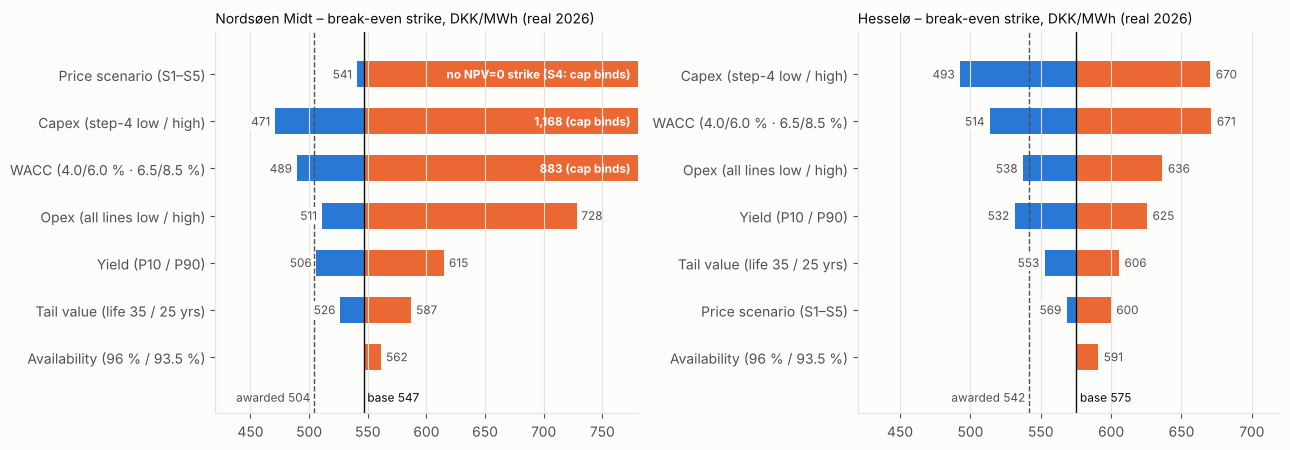

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, s in zip(axes, d.SITES):
    t = torn[torn.site == s].copy()
    t["swing_plot"] = t["high"].clip(upper=2000).fillna(2000) - t["low"]
    t = t.sort_values("swing_plot")
    base = BE[s]; xmax = 780 if s == "NSM" else 720
    for i, r in enumerate(t.itertuples()):
        vals = sorted([r.low, r.high if np.isfinite(r.high) else np.inf])
        lo_v, hi_v = vals
        ax.barh(i, max(base - lo_v, 0), left=min(lo_v, base), height=0.55, color=PAL[0])   # favourable
        ax.barh(i, max(min(hi_v, xmax) - base, 0), left=base, height=0.55, color=PAL[1])     # adverse
        if lo_v < base - 1:
            ax.text(lo_v - 4, i, f"{lo_v:.0f}", va="center", ha="right", fontsize=8.5, color=INK2,
                    bbox=dict(boxstyle="square,pad=0.1", fc=SURF, ec="none"))
        if not np.isfinite(hi_v):
            lab, x = "no NPV=0 strike (S4: cap binds)", xmax
        elif hi_v > xmax:
            lab, x = f"{hi_v:,.0f} (cap binds)", xmax
        else:
            lab, x = f"{hi_v:.0f}", hi_v
        if x < xmax:
            ax.text(x + 4, i, lab, va="center", ha="left", fontsize=8.5, color=INK2)
        else:
            ax.text(x - 6, i, lab, va="center", ha="right", fontsize=8.5, color="white", fontweight="bold")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t["input"])
    ax.axvline(base, color=INK, lw=1); ax.axvline(BASE[s].strike, color=INK2, lw=1, ls="--")
    ax.text(BASE[s].strike - 3, -0.95, f"awarded {BASE[s].strike:.0f}", ha="right", fontsize=8.5, color=INK2)
    ax.text(base + 3, -0.95, f"base {base:.0f}", ha="left", fontsize=8.5)
    ax.set_xlim(420, xmax); ax.set_ylim(-1.2, len(t) - 0.1); ax.grid(axis="y", visible=False)
    ax.set_title(f"{d.SITES[s]['name']} – break-even strike, DKK/MWh (real 2026)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "fig_tornado.png", dpi=150)

## 7. Paired sensitivity — DEA 2025 column with 15 MW turbines vs 2030 column with 20 MW turbines
- **A. 2025 column / 15 MW:** DEA FID-2025 capex (site-adjusted, + base 7.5 % contingency and owner devex), fixed O&M
  €44k and variable €4.41 (2025 column), yield = step-2 15 MW model (Ext + Asm).
- **B. 2030 column / 20 MW:** base capex and O&M (2030 column), yield +3.4 % (DEA full-load hours 4,550 vs 4,400; S5-13).
- The base case mixes the two (2030 cost, 15 MW yield) and is therefore slightly conservative on yield.
- Last column: the CfD WACC at which each case just reaches NPV = 0 at the awarded strike. The difference
  B − A is the extra return (technology-risk premium) that a 20 MW bet can carry and still beat the 15 MW route.

In [17]:
U20 = 4550 / 4400
paired_cases = {
    "A. 2025 column, 15 MW": dict(capex_case="col2025", fixed_om_case="high", var_om_case="high"),
    "Base (2030 cost, 15 MW yield)": dict(),
    "B. 2030 column, 20 MW": dict(yield_factor=U20),
}
rows = []
for s in d.SITES:
    for name, kw in paired_cases.items():
        p = case_params(s, **kw)
        rows.append({"site": s, "case": name, "capex DKK m/MW": p.capex_per_mw,
                     "fixed O&M+ins. DKK k/MW": p.fixed_om_k_per_mw + p.insurance_k_per_mw,
                     "AAP GWh": p.aap_monthly.sum() * p.yield_factor / 1e3,
                     "BE strike @ 5/7 %": d.breakeven_strike(p, SC[s]["S1"]),
                     "BE strike @ 5.5/7.5 %": d.breakeven_strike(replace(p, wacc_cfd=0.055, wacc_tail=0.075), SC[s]["S1"]),
                     "BE strike @ 6.0/8.0 %": d.breakeven_strike(replace(p, wacc_cfd=0.06, wacc_tail=0.08), SC[s]["S1"]),
                     "CfD WACC for NPV=0 @ awarded (%)": 100 * d.solve_wacc(p, SC[s]["S1"])})
paired = pd.DataFrame(rows).set_index(["site", "case"])
paired.to_csv(OUT / "paired_2025_vs_2030.csv", float_format="%.2f")
paired.apply(lambda col: col.map(lambda v: f"{v:,.1f}" if np.isfinite(v) else "cap-limited") if col.name.startswith("BE") else col)

capex DKK m/MW  fixed O&M+ins. DKK k/MW  AAP GWh BE strike @ 5/7 % BE strike @ 5.5/7.5 % BE strike @ 6.0/8.0 %  CfD WACC for NPV=0 @ awarded (%)
site case                                                                                                                                                                           
NSM  A. 2025 column, 15 MW                    26.0                    466.6  4,820.2       cap-limited           cap-limited           cap-limited                               2.6
     Base (2030 cost, 15 MW yield)            22.3                    377.5  4,820.2             546.6                 589.1                 694.0                               4.3
     B. 2030 column, 20 MW                    22.3                    377.5  4,984.5             528.1                 556.9                 628.7                               4.6
HES  A. 2025 column, 15 MW                    25.9                    466.6  3,589.3             688.7                 724.2                 779.6                               2.8
     Base (2030 cost, 15 MW yield)            22.2                    377.5  3,589.3             574.9                 606.3                 638.3                               4.5
     B. 2030 column, 20 MW                    22.2                    377.5  3,711.7             555.3                 585.8                 617.0                               4.8

## 8. Internal wake 12–13 % (vs 10 % base)
Lowers AAP and metered output pro rata (B1/C3: AAP is net of wakes, Doc). This is the step-2 alternative that would
bring our yield close to the DEA's interim NSM estimate (4,479 GWh, B11).

In [18]:
rows = []
for s in d.SITES:
    for w in (0.10, 0.12, 0.13):
        p = case_params(s, internal_wake=w)
        rows.append({"site": s, "internal wake": f"{w:.0%}", "AAP GWh": p.aap_monthly.sum() * p.aap_factor / 1e3,
                     "NPV @ awarded (DKK m)": d.npv(p, SC[s]["S1"]),
                     "BE strike": d.breakeven_strike(p, SC[s]["S1"]),
                     "CfD WACC for NPV=0 (%)": 100 * d.solve_wacc(p, SC[s]["S1"])})
wake = pd.DataFrame(rows).set_index(["site", "internal wake"])
wake.to_csv(OUT / "wake_case.csv", float_format="%.2f")
wake

AAP GWh  NPV @ awarded (DKK m)  BE strike  CfD WACC for NPV=0 (%)
site internal wake                                                                   
NSM  10%            4,820.2               -1,471.8      546.6                     4.3
     12%            4,713.0               -1,869.7      559.4                     4.1
     13%            4,659.5               -2,068.7      566.0                     3.9
HES  10%            3,589.3                 -844.9      574.9                     4.5
     12%            3,509.5               -1,166.0      588.4                     4.3
     13%            3,469.7               -1,326.5      595.4                     4.1

## 9. Other modelling choices (one at a time, S1)

In [19]:
other = {
    "Base": lambda s: BASE[s],
    "Tail discounted at tail WACC from today ('full')": lambda s: replace(BASE[s], tail_discounting="full"),
    "Strike indexation lag (Sep(y−1) NPI reset, A4)": lambda s: replace(BASE[s], strike_indexation="lagged"),
    "No payment lag (B7 off)": lambda s: replace(BASE[s], payment_lag_months=0),
    "No net cap (B9 off)": lambda s: replace(BASE[s], apply_cap=False),
    "Standalone tax (SEL §12)": lambda s: replace(BASE[s], tax_mode="standalone"),
    "Export cable at 15 % (§5C stk. 1)": lambda s: replace(BASE[s], export_rate=0.15),
    "Early phasing (FID 2028)": lambda s: case_params(s, phasing="early"),
    "Late phasing (FID 2030)": lambda s: case_params(s, phasing="late"),
    "Energinet contribution high": lambda s: case_params(s, energinet_case="high"),
    "Decommissioning 15 %": lambda s: case_params(s, decom_case="high"),
}
rows = []
for name, f in other.items():
    row = {"case": name}
    for s in d.SITES:
        p = f(s)
        row[f"{s} NPV"] = d.npv(p, SC[s]["S1"])
        row[f"{s} BE strike"] = d.breakeven_strike(p, SC[s]["S1"])
    rows.append(row)
other_tbl = pd.DataFrame(rows).set_index("case")
other_tbl.to_csv(OUT / "other_checks.csv", float_format="%.1f")
other_tbl

,NSM NPV,NSM BE strike,HES NPV,HES BE strike
case,,,,
Base,"-1,471.8",546.6,-844.9,574.9
Tail discounted at tail WACC from today ('full'),"-2,176.9",567.1,"-1,418.2",597.2
"Strike indexation lag (Sep(y−1) NPI reset, A4)","-1,741.3",555.2,"-1,061.4",583.9
No payment lag (B7 off),"-1,447.9",545.7,-826.2,573.9
No net cap (B9 off),"-1,471.8",546.6,-844.9,574.9
Standalone tax (SEL §12),"-1,732.4",552.4,"-1,014.9",580.2
Export cable at 15 % (§5C stk. 1),"-1,440.5",545.7,-810.9,573.5
Early phasing (FID 2028),"-1,970.6",561.1,"-1,244.6",590.4
Late phasing (FID 2030),-867.3,529.1,-360.4,556.0


## 10. Headline numbers for the memo

In [20]:
head = {}
for s in d.SITES:
    g = wacc_grid[(wacc_grid.site == s)]
    head[s] = {
        "BE strike base": BE[s], "awarded": BASE[s].strike,
        "implied CfD WACC at base capex": float(summary.loc["Implied CfD WACC at awarded strike (%)", s]),
        "capex for NPV=0 at 5 %": float(be_capex.loc["P50", s]),
        "BE strike S1-B′": d.breakeven_strike(BASE[s], SC[s]["S1_Bprime"]),
    }
pd.DataFrame(head)

,NSM,HES
BE strike base,546.6,574.9
awarded,504.0,542.0
implied CfD WACC at base capex,4.3,4.5
capex for NPV=0 at 5 %,20.2,20.7
BE strike S1-B′,683.4,606.8
